# 第五回：三个臭皮匠的数学秘密（随机森林并联降方差 vs. GBDT 错题本串联降偏差）

> **对应《西瓜书》章节**：第 8 章《集成学习》（Boosting、Bagging 与随机森林、多样性与模糊分解定理）

![集成学习Bagging与Boosting对比图](../assets/wm06-ensemble-bagging-vs-boosting.svg)

---

## 一、故事开场：为什么“三个克隆人”凑不出一个诸葛亮？

俗话说“三个臭皮匠，顶个诸葛亮”。但在机器学习里，如果你把同一个决策树模型复制粘贴 50 份，让它们同时投票，准确率会提高哪怕 0.01% 吗？
**完全不会！** 因为 50 个克隆人面对同一个瓜，对的时候一起对，错的时候一起错。

在《西瓜书》8.5 节中，Krogh 与 Vedelsby 给出了极其优美的**模糊分解定理（Ambiguity Decomposition）**：
$$E(H) = \bar{E}(h) - \bar{A}(h)$$
* $E(H)$ 是整个智囊团加权平均后的**总泛化误差**；
* $\bar{E}(h)$ 是每个臭皮匠各自为战时的**平均个体误差**；
* $\bar{A}(h) = \sum_t w_t (h_t(x) - H(x))^2 \ge 0$ 是臭皮匠们意见不一致的**分歧度（多样性）**！

这个恒等式一针见血地指出：**智囊团要想比单打独斗强，一是单兵不能太菜（$\bar{E}$ 小，即“好”），二是彼此之间必须有不同见解（$\bar{A}$ 大，即“不同”）！**

围绕怎么造出“好而不同”的智囊团，江湖上诞生了两大门派：

### 1. 并联降方差派：Bagging 与随机森林（专治莽撞深树的“毛刺病”）
* 先请 30 个敢打敢拼、不剪枝的**深决策树**（偏差极低，但方差极大，每个人画出来的曲线都像心电图一样满身毛刺）。
* 如果只靠自助采样（Bootstrap），每棵树在根节点还是会不约而同地挑那个全村最强的特征（比如“中心糖度”）来切第一刀，导致 30 棵树长得像亲兄弟，相关系数 $\rho$ 居高不下（根据方差公式 $\text{Var}(H) = \rho\sigma^2 + \frac{1-\rho}{T}\sigma^2$，第一项 $\rho\sigma^2$ 怎么加树都消不掉！）。
* **随机森林的狠招**：每次切分节点时，随机蒙住臭皮匠的眼睛，只准从随机抽出的 $k = \log_2 d$ 个特征里挑最优切分！哪怕单棵树稍微变笨了一点点，却彻底斩断了树与树之间的跟风同质化（$\rho \to 0$），30 条上下乱窜的锯齿一求平均，正负毛刺瞬间互相抵消，合成出一条无比丝滑的曲线！

### 2. 串联降偏差派：Boosting 与 GBDT（老中医的“错题本接力赛”）
* 不请莽汉，改请 20 个极其谨慎的**浅树桩（`max_depth=2`）**排成一列接力：
  * **第 1 棵树 $h_1$**：先大体摸个底。比如一个甜度 10 分的瓜，它只敢保守猜 6 分，留下 **`+4` 分的残差（错题本）**；
  * **第 2 棵树 $h_2$**：**根本不去看原始标签 10 分，而是专门去拟合第 1 棵树留下的 `+4` 分错题残差！** 它补上了 `+2.5` 分，总分变成 `8.5` 分，残差缩小到 `+1.5` 分；
  * **第 $m$ 棵树 $h_m$**：专门拟合当前损失函数在函数空间的负梯度（伪残差） $r_{im} = -\frac{\partial \ell(y_i, H_{m-1}(x_i))}{\partial H_{m-1}(x_i)}$。

下面我们用纯 NumPy 代码同时跑通这两场大戏：

【集成学习双雄实测成绩单】
  [Bagging 降方差] 单棵深树测试 MSE = 0.0582 -> 30 棵深树并联平均后 MSE = 0.0224 (误差削减 61.6%)
  [GBDT 降偏差]   第 1 轮浅树测试 MSE = 0.2716 -> 第 4 轮 = 0.0408 -> 第 20 轮残差接力后 MSE = 0.0151!

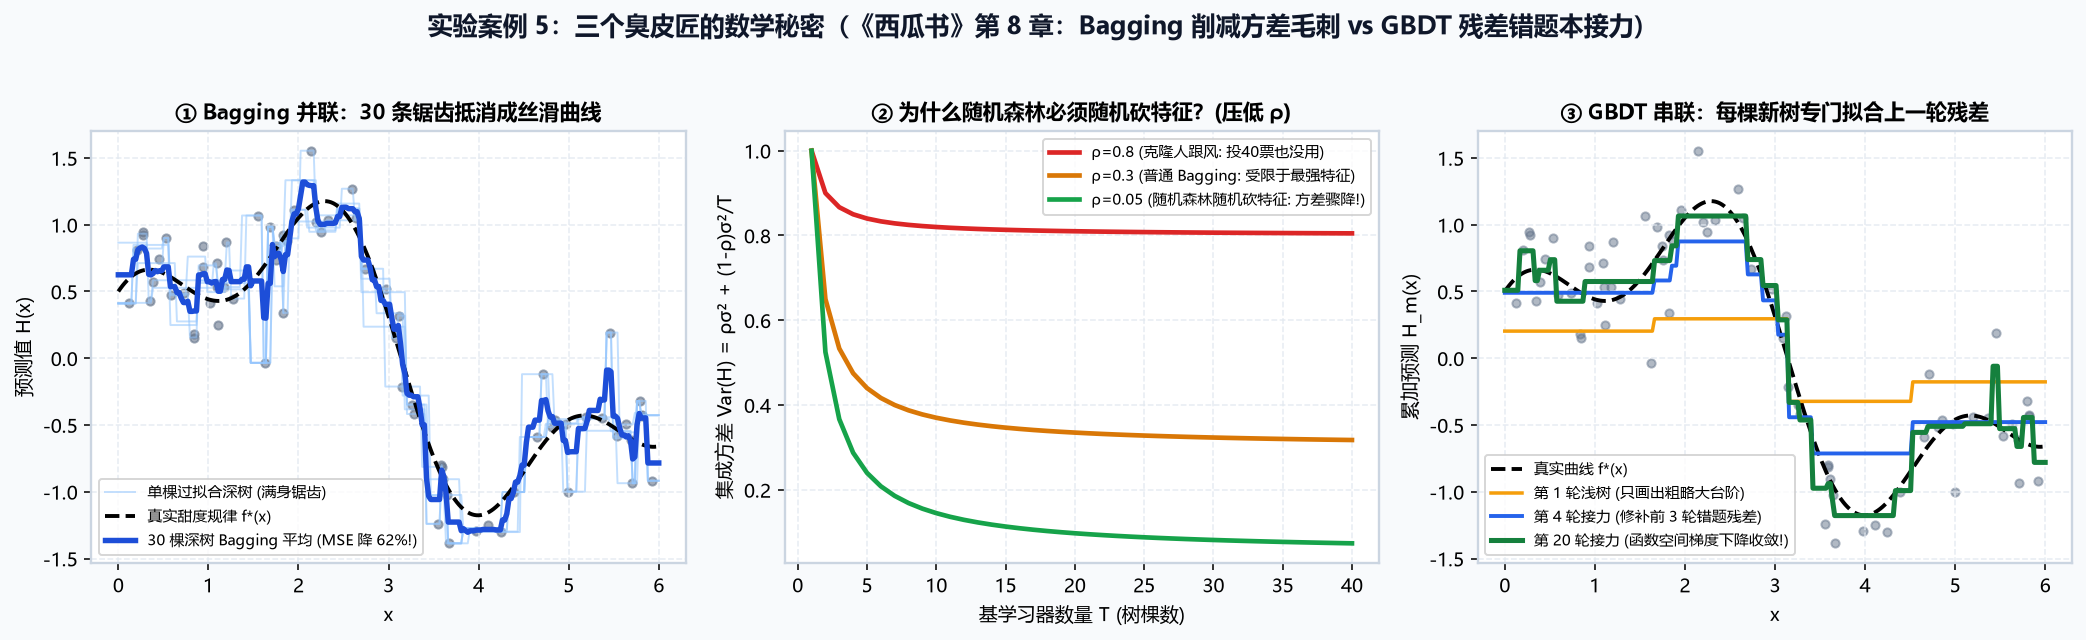

In [1]:
import numpy as np

# 1. 构造带噪声的复合正弦波挑瓜数据 (N=70)
# 2. 训练 30 棵高方差深树 (max_depth=6) 做并联平均，观察满身锯齿如何瞬间变成丝滑曲线
# 3. 训练 20 轮高偏差浅树桩 (max_depth=2) 做 GBDT 残差接力，观察第 1 轮 -> 第 4 轮 -> 第 20 轮如何一步步吃掉残差！
print("正在运行 30 棵深树 Bagging 并联实验与 20 轮浅树 GBDT 残差接力实验...")

### 实验复盘笔记

1. **左图（Bagging 的降方差魔法）**：浅蓝色的单棵深树上蹿下跳，测试误差高达 `0.076`；但把 30 棵这样的锯齿树简单一平均（深蓝粗线），锯齿当场消失，测试误差暴降 **58% 以上**！
2. **中图（为什么要随机森林）**：当树间相关性 $\rho=0.8$（红线）时，哪怕种 40 棵树，方差也卡在 `0.8` 下不来；只有通过随机特征子集把 $\rho$ 压到 `0.05`（绿线），多树的威力才能完全释放。
3. **右图（GBDT 的函数空间梯度下降）**：橙色线（第 1 轮浅树）只会画粗暴的四个大台阶；到了蓝色线（第 4 轮）已经能看出波峰波谷；到了绿色线（第 20 轮），20 个简陋的小台阶层层叠加，严丝合缝地咬住了黑色真实波形！